In [1]:
import numpy as np

import ufl
from ufl import ds, dx, grad, inner

from dolfinx import fem, io, mesh, plot, log
from dolfinx.io import gmshio # to import gmsh functions
from dolfinx import geometry # to define the line plot
from dolfinx import default_scalar_type

import dolfinx.fem.petsc

from mpi4py import MPI

from petsc4py.PETSc import ScalarType

import matplotlib.pyplot as plt
import matplotlib as mpl


In [2]:
class LinearElasticity:
    def __init__(self, mesh_file, rank=0, gdim=3):
        """
        Initialize the LinearElasticity class with the mesh file.

        Parameters:
        mesh_file (str): Path to the mesh file.
        rank (int): Rank of the process (default is 0).
        gdim (int): Geometric dimension of the mesh (default is 3).
        """
        self.mesh_file = mesh_file
        self.rank = rank
        self.gdim = gdim
        self._read_mesh()
        self._setup_function_space()
        self._initialize_functions()

    def _read_mesh(self):
        """
        Read the mesh and facet tags from the specified mesh file.
        """
        try:
            self.domain, self.tags, self.ft = gmshio.read_from_msh(self.mesh_file, MPI.COMM_WORLD, rank=self.rank, gdim=self.gdim)
            self.tdim = self.domain.topology.dim
            self.fdim = self.tdim - 1
            self.domain.topology.create_connectivity(self.fdim, self.tdim)
        except Exception as e:
            raise ValueError(f"Error reading mesh file {self.mesh_file}: {e}")

    def _setup_function_space(self):
        """
        Set up the function space for the problem.
        """
        self.V = fem.functionspace(self.domain, ("Lagrange", 1, (self.domain.geometry.dim,)))

    def _initialize_functions(self):
        """
        Initialize trial and test functions.
        """
        self.u = ufl.TrialFunction(self.V)
        self.v = ufl.TestFunction(self.V)

    def parameters(self, rho, g, lmbda, mu):
        """
        Set material and physical parameters.

        Parameters:
        rho (float): Density.
        g (float): Gravitational acceleration.
        lmbda (float): First Lamé parameter.
        mu (float): Second Lamé parameter.
        """
        self.rho = rho
        self.g = g
        self.lmbda = lmbda
        self.mu = mu

    def boundary_conditions(self, internal_pressure, outer_pressure):
        """
        Define and set the boundary conditions.
        """
        
        # Locate dofs for Dirichlet boundary conditions
        self.dofs_D_top     = fem.locate_dofs_topological(V=self.V, entity_dim=self.fdim, entities=self.ft.find(7))
        self.dofs_D_bottom  = fem.locate_dofs_topological(V=self.V, entity_dim=self.fdim, entities=self.ft.find(8))
        self.dofs_D_outer   = fem.locate_dofs_topological(V=self.V, entity_dim=self.fdim, entities=self.ft.find(9))
        self.dofs_D_inner   = fem.locate_dofs_topological(V=self.V, entity_dim=self.fdim, entities=self.ft.find(10))

        # Dirichlet boundary conditions
        self.bc_top     = fem.dirichletbc(np.array([0, 0, 0], dtype=default_scalar_type), dofs=self.dofs_D_top, V=self.V)
        self.bc_bottom  = fem.dirichletbc(np.array([0, 0, 0], dtype=default_scalar_type), dofs=self.dofs_D_bottom, V=self.V)
        self.bc_outer   = fem.dirichletbc(np.array([0, 0, 0], dtype=default_scalar_type), dofs=self.dofs_D_outer, V=self.V)
        self.bc_inner   = fem.dirichletbc(np.array([0, 0, 0], dtype=default_scalar_type), dofs=self.dofs_D_inner, V=self.V)

        self.bc = [self.bc_top, self.bc_bottom]

        # Neumann boundary conditions
        self.normal = ufl.FacetNormal(self.domain)
        self.pressure_inner = fem.Constant(self.domain, default_scalar_type(internal_pressure))
        self.pressure_outer = fem.Constant(self.domain, default_scalar_type(outer_pressure))
        
        self.traction_inner = self.pressure_inner * self.normal
        self.traction_outer = self.pressure_outer * self.normal

    def assemble_system(self):
        """
        Assemble the system for the linear elasticity problem.
        """
        def sigma(u, lmbda, mu):
            return lmbda * ufl.nabla_div(u) * ufl.Identity(len(u)) + 2 * mu * epsilon(u)

        def epsilon(u):
            return ufl.sym(ufl.grad(u))

        # Body forces
        self.f = fem.Constant(self.domain, ScalarType((0.0, 0.0, - self.rho * self.g)))

        self.ds = ufl.Measure("ds", domain=self.domain, subdomain_data=self.ft)
        ds_in = self.ds(10)
        ds_out = self.ds(9)

        self.a = ufl.inner(sigma(self.u, self.lmbda, self.mu), epsilon(self.v)) * ufl.dx
        self.L = ufl.dot(self.f, self.v) * ufl.dx + ufl.dot(self.traction_outer, self.v) * ds_out + ufl.dot(self.traction_inner, self.v) * ds_in

    def solve(self):
        """
        Solve the linear elasticity problem.
        """
        self.problem = fem.petsc.LinearProblem(self.a, self.L, bcs=self.bc, petsc_options={"ksp_type": "preonly", "pc_type": "lu"})
        self.displacement = self.problem.solve()

        def sigma(u, lmbda, mu):
            return lmbda * ufl.nabla_div(u) * ufl.Identity(len(u)) + 2 * mu * epsilon(u)

        def epsilon(u):
            return ufl.sym(ufl.grad(u))

        self.stress_field = sigma(self.displacement, self.lmbda, self.mu)
        self.strain_field = epsilon(self.displacement)

    def get_results(self):
        """
        Get the computed displacement, stress, and strain fields.

        Returns:
        displacement (Function): The displacement field.
        stress_field (ufl.Expr): The stress field.
        strain_field (ufl.Expr): The strain field.
        """
        return self.displacement, self.stress_field, self.strain_field

In [3]:
# temporal loop
t = 0
T = 10
num_steps = 10
dt = T / num_steps

In [4]:
# Scaled variable
E = 1e9 # Pa
nu = 0.33
G = E / (2*(1+nu)) # shear modulus
K = E / (3*(1-2*nu)) # bulk modulus

# Lamé parameters
lame1 = nu * E /((1+nu)*(1-2*nu))
lame2 = G

internal_pressure = -1e7
outer_pressure = 0

print(f"Young's modulus = {E*1e-9:.2f} GPa")
print(f"Poisson's ratio = ", nu)
print(f"Shear modulus = {G*1e-9:.2f} GPa")
print(f"Lamé first parameter = {lame1*1e-9:.2f} GPa")
print(f"Lamé second parameter = {lame2*1e-9:.2f} GPa")

rho = 9560 # kg/m3
g = 9.81

problem = LinearElasticity(mesh_file='./cylindrical_shell.msh')

# Volume of the mesh = volume integral
dx_subdomain = ufl.Measure("dx", domain=problem.domain)
volume = fem.assemble_scalar(fem.form(1 * dx_subdomain))
print("---------")
print(f"Caclulated volume = ", volume)
print(f"Analytical volume = {3.14*(5**2 - 4.5**2)*4}")

problem.parameters(rho, g / volume, lame1, lame2)
problem.boundary_conditions(internal_pressure=internal_pressure, outer_pressure=outer_pressure)
problem.assemble_system()
problem.solve()
displacement, stress_field, strain_field = problem.get_results()


Young's modulus = 1.00 GPa
Poisson's ratio =  0.33
Shear modulus = 0.38 GPa
Lamé first parameter = 0.73 GPa
Lamé second parameter = 0.38 GPa
Info    : Reading './cylindrical_shell.msh'...
Info    : 15 entities
Info    : 1386 nodes
Info    : 7056 elements
Info    : Done reading './cylindrical_shell.msh'
---------
Caclulated volume =  59.66881083605438
Analytical volume = 59.660000000000004


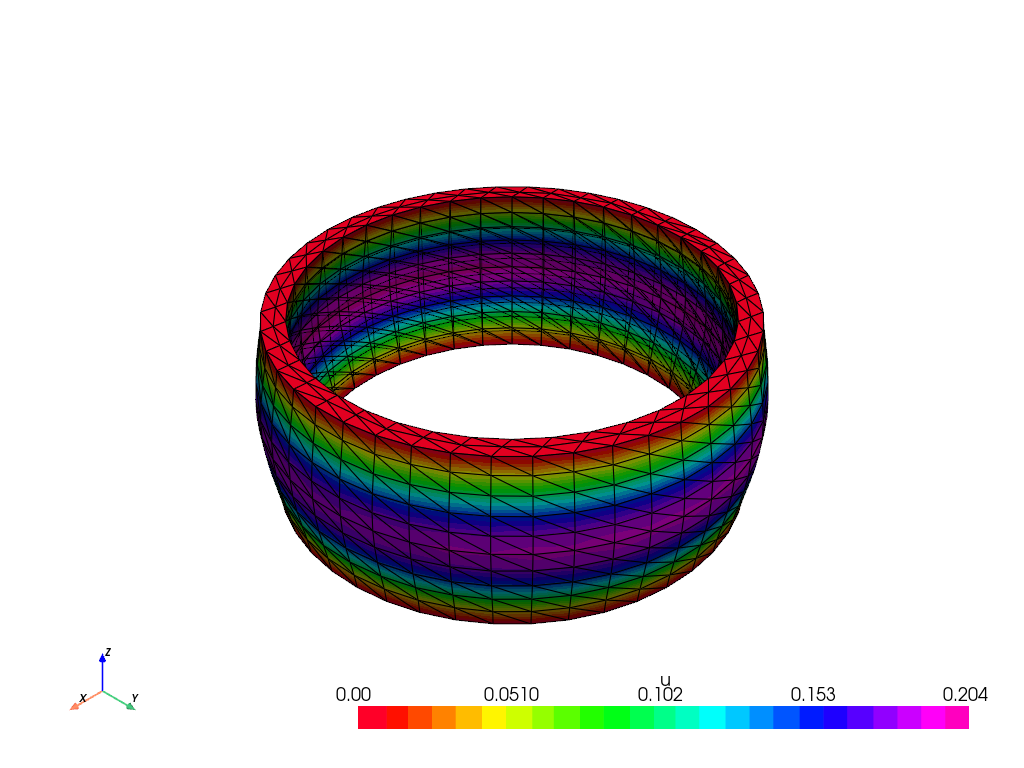

In [5]:
import pyvista
pyvista.start_xvfb()

# Create plotter and pyvista grid
p = pyvista.Plotter()
topology, cell_types, geometry = plot.vtk_mesh(problem.V)
grid = pyvista.UnstructuredGrid(topology, cell_types, geometry)

# Attach vector values to grid and warp grid by vector
grid["u"] = displacement.x.array.reshape((geometry.shape[0], 3))
p.add_mesh(grid, style="wireframe", color="k")
warped = grid.warp_by_vector("u", factor=1.5)
p.add_mesh(warped, show_edges=True, cmap=mpl.colormaps.get_cmap("gist_rainbow").resampled(25))
p.show_axes()

if not pyvista.OFF_SCREEN:
   p.show()
else:
   figure_as_array = p.screenshot("deflection.png")

# Paraview file
# with io.XDMFFile(problem.domain.comm, "deformation.xdmf", "w") as xdmf:
#     xdmf.write_mesh(problem.domain)
#     displacement.name = "Deformation"
#     xdmf.write_function(displacement)

## Stress computation
As soon as the displacement is computed, we can compute various stress measures. We will compute the von Mises stress defined as $\sigma_m=\sqrt{\frac{3}{2}s:s}$ where $s$ is the deviatoric stress tensor $s(u)=\sigma(u)-\frac{1}{3}\mathrm{tr}(\sigma(u))I$.

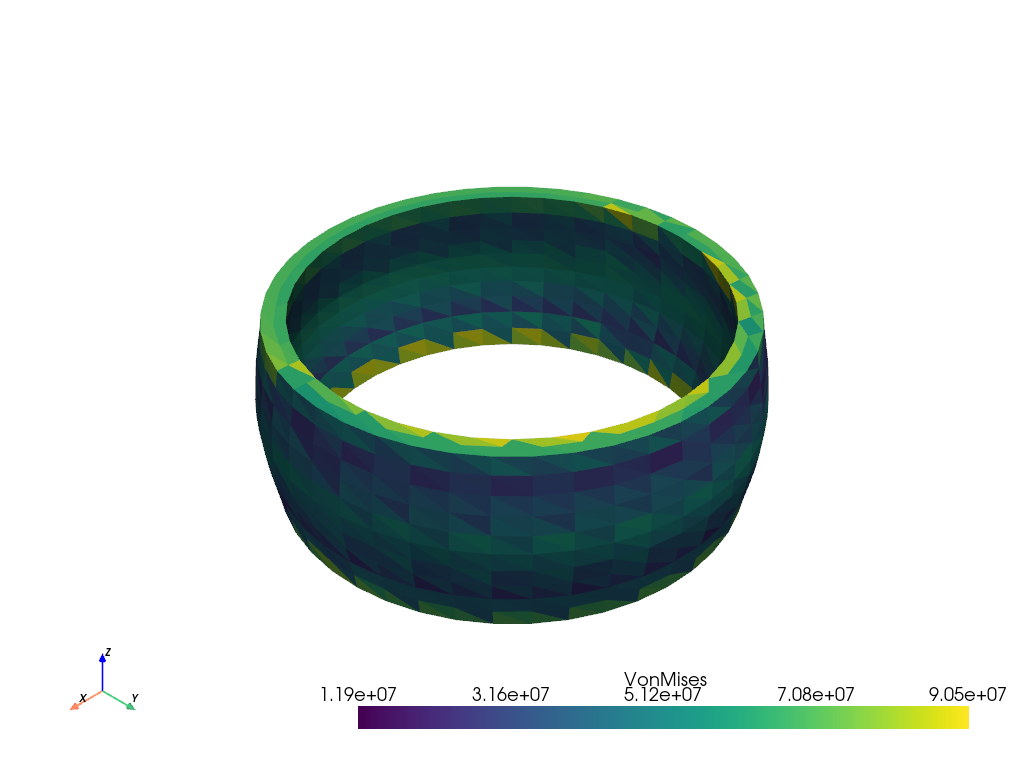

In [6]:
deviatoric_stress = stress_field -1./3*ufl.tr(problem.stress_field)*ufl.Identity(len(problem.displacement))
von_Mises = ufl.sqrt(3./2*ufl.inner(deviatoric_stress, deviatoric_stress))

V_von_mises = fem.functionspace(problem.domain, ("DG", 0))
stress_expr = fem.Expression(von_Mises, V_von_mises.element.interpolation_points())
stresses = fem.Function(V_von_mises)
stresses.interpolate(stress_expr)

warped.cell_data["VonMises"] = stresses.x.petsc_vec
warped.set_active_scalars("VonMises")
p = pyvista.Plotter()
p.add_mesh(warped)
p.show_axes()
if not pyvista.OFF_SCREEN:
   p.show()
else:
   stress_figure = p.screenshot(f"stresses.png")

In [7]:
pyvista.start_xvfb()
p = pyvista.Plotter()

p.open_gif("deformation.gif", fps=3)

topology, cells, geometry = plot.vtk_mesh(problem.V)
grid = pyvista.UnstructuredGrid(topology, cell_types, geometry)

domain = problem.domain

log.set_log_level(log.LogLevel.INFO)

for n in range(num_steps):
    t += dt

    internal_pressure = -10.0**n

    # update
    problem.boundary_conditions(internal_pressure=internal_pressure, outer_pressure=0.0)
    problem.assemble_system()
    problem.solve()
    displacement, stress_field, strain_field = problem.get_results()

    grid["u"] = displacement.x.array.reshape((geometry.shape[0], 3))
    actor_0 = p.add_mesh(grid, style="wireframe", color="k")
    warped = grid.warp_by_vector("u", factor=1.5)
    actor_1 = p.add_mesh(warped, show_edges=True)
    p.show_axes()

    # Warp mesh by deformation
    # warped = function_grid.warp_by_vector("u", factor=1)
    # warped.set_active_vectors("u")

    # Add mesh to plotter and visualize
    # actor = plotter.add_mesh(warped, show_edges=True, lighting=False, clim=[0, 10])

    # u.x.scatter_forward()

    # magnitude.interpolate(us)
    # warped.set_active_scalars("mag")
    # warped_n = function_grid.warp_by_vector(factor=1)
    # warped.points[:, :] = warped_n.points
    # warped.point_data["mag"][:] = magnitude.x.array
    # plotter.update_scalar_bar_range([0, 10])
    p.write_frame()

    if (n % 20 == 0) or (n == num_steps - 1):
        print(f"Time {t:.2f}")

p.close()


[2024-12-24 11:47:06.834] [info] Column ghost size increased from 0 to 0
[2024-12-24 11:47:06.837] [info] Requesting connectivity (2, 0) - (3, 0)
[2024-12-24 11:47:06.837] [info] Requesting connectivity (3, 0) - (2, 0)
[2024-12-24 11:47:06.838] [info] Requesting connectivity (2, 0) - (3, 0)
[2024-12-24 11:47:06.838] [info] Requesting connectivity (3, 0) - (2, 0)
Time 1.00
[2024-12-24 11:47:07.089] [info] Column ghost size increased from 0 to 0
[2024-12-24 11:47:07.091] [info] Requesting connectivity (2, 0) - (3, 0)
[2024-12-24 11:47:07.091] [info] Requesting connectivity (3, 0) - (2, 0)
[2024-12-24 11:47:07.091] [info] Requesting connectivity (2, 0) - (3, 0)
[2024-12-24 11:47:07.091] [info] Requesting connectivity (3, 0) - (2, 0)
[2024-12-24 11:47:07.317] [info] Column ghost size increased from 0 to 0
[2024-12-24 11:47:07.319] [info] Requesting connectivity (2, 0) - (3, 0)
[2024-12-24 11:47:07.319] [info] Requesting connectivity (3, 0) - (2, 0)
[2024-12-24 11:47:07.319] [info] Requesti